# Phase 7 — Exploratory Data Analysis

Describes price behaviour, market-arrival patterns, seasonality, weather/APY associations and data limitations for Onion, Potato and Wheat, and assembles the evidence for three decisions that must be made before modelling. Summary computations live in `Code/eda/analysis.py` and are written to `Processed_Data/eda/`; this notebook explains them and draws the figures. **No model is trained and nothing is forecast.**

## INDEX

1. [Objective, Scope and Rules](#1)
2. [Inputs, Column Roles and Analysis Samples](#2)
3. [Run the EDA Computations](#3)
4. [Price EDA](#4)
5. [Market-Arrivals EDA](#5)
6. [Price–Arrivals Association](#6)
7. [Weather Association](#7)
8. [APY Association](#8)
9. [Data Quality and Modelling Readiness](#9)
10. [Decision A — Forecast Horizon and Information Cutoff](#10)
11. [Decision B — Flagged Observations](#11)
12. [Decision C — Evaluation Split](#12)
13. [Validation](#13)
14. [Findings, Limitations and Phase 8 Handoff](#14)


<a id="1"></a>
## 1. Objective, Scope and Rules

- Columns are used by their **Phase 6 registry role** (identifier, target, predictor, eligibility_flag, audit_only) — the 85 columns are not all treated as predictors.
- Every statistic states its **sample**: `all_rows`, `price_present`, `usable_price`, `usable_price_excl_review`, `usable_arrivals`, `usable_arrivals_excl_review` (definitions in `sample_definitions.csv`).
- Crops are analysed **separately**; cross-crop comparisons use relative measures (seasonal indices, coefficients of variation), not raw rupee levels.
- **Prices are nominal Rs/quintal. No inflation adjustment is performed anywhere**; long-run comparisons of rupee levels mix real change with general inflation. Seasonal indices divide each price by its own series-year median, which removes the year's price level.
- Associations are **not causal** evidence. Arrivals measure market-supply activity, not consumer demand and not total production.
- Flagged and conflicting records are never silently dropped: their counts are reported, and their effect on conclusions is measured.

<a id="2"></a>
## 2. Inputs, Column Roles and Analysis Samples

In [1]:
import os, sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

from Code.eda import analysis as e
from Code.features import pipeline as f6
from Code.integration import pipeline as p4

CROPS = p4.load_selected_crops()
FIG = Path("Outputs/Figures")
registry = pd.read_csv(f6.AUDIT_DIR / "feature_registry.csv")
print("Column roles in the Phase 6 registry:")
print(registry["role"].value_counts().to_string())
pd.read_csv(f6.AUDIT_DIR / "row_counts.csv")

Column roles in the Phase 6 registry:
role
predictor           59
audit_only          10
identifier           9
target               4
eligibility_flag     2


,crop,input_rows,output_rows,series,input_columns,output_columns,rows_with_usable_modal_target,rows_with_usable_arrivals_target
0,Onion,2623671,2623671,3924,47,85,2595611,2623528
1,Potato,2764417,2764417,4003,47,85,2731271,2764191
2,Wheat,2593279,2593279,5279,47,85,2579015,2593120


<a id="3"></a>
## 3. Run the EDA Computations

Reads the three Phase 6 feature tables (fingerprinted before and after; never modified) and writes 15 summary tables to `Processed_Data/eda/`.

In [2]:
import logging
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
R = e.run_eda()
print("Run time (s):", R["seconds"])
R["sample_definitions"].pivot(index=["sample", "definition"], columns="crop", values="rows")

Onion done


Potato done


Wheat done


Phase 7 EDA tables written in 75.9s


Run time (s): 75.9


,crop,Onion,Potato,Wheat
sample,definition,,,
all_rows,every Phase 6 row (incl. conflicts and flagged rows),2623671,2764417,2593279
price_present,rows with a non-missing modal price (any flag),2596197,2731906,2579948
usable_arrivals,usable_arrivals = True (Phase 5 view),2623528,2764191,2593120
usable_arrivals_excl_review,usable_arrivals and arrivals_extreme_level != review,2623129,2763792,2592636
usable_price,usable_modal_price = True (Phase 5 view),2595611,2731271,2579015
usable_price_excl_review,usable_modal_price and price_extreme_level != review,2573328,2728946,2578561


In [3]:
SERIES_C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOR = dict(zip(CROPS, SERIES_C))

<a id="4"></a>
## 4. Price EDA

### 4a. Distribution (Rs/quintal, nominal) under three samples

In [4]:
dist = R["distribution_summary"]
dist[dist["variable"] == f6.MODAL].drop(columns="variable").round(1)

,crop,sample,rows_in_sample,non_missing,min,mean,std,p01,p05,p25,p50,p75,p95,p99,max,cv
0,Onion,price_present,2596197,2596197,0.2,1606.0,1328.9,280.0,415.0,800.0,1300.0,2000.0,4000.0,5850.0,460000.0,0.8
1,Onion,usable_price,2595611,2595611,6.0,1605.6,1265.4,280.0,420.0,800.0,1300.0,2000.0,4000.0,5850.0,82000.0,0.8
2,Onion,usable_price_excl_review,2573328,2573328,40.0,1602.5,1182.7,287.5,425.0,800.0,1300.0,2000.0,4000.0,5800.0,38380.0,0.7
6,Potato,price_present,2731906,2731906,1.0,1044.1,6822.1,200.0,300.0,550.0,850.0,1300.0,2500.0,3500.0,11200000.0,6.5
7,Potato,usable_price,2731271,2731271,7.0,1039.7,785.0,200.0,300.0,550.0,850.0,1300.0,2500.0,3500.0,71000.0,0.8
8,Potato,usable_price_excl_review,2728946,2728946,40.0,1035.0,696.4,200.0,300.0,550.0,850.0,1300.0,2500.0,3500.0,12180.0,0.7
12,Wheat,price_present,2579948,2579948,1.0,1575.4,577.2,650.0,800.0,1185.0,1580.0,1883.0,2400.0,2800.0,148000.0,0.4
13,Wheat,usable_price,2579015,2579015,100.0,1574.5,494.2,650.0,800.0,1185.0,1580.0,1881.0,2400.0,2800.0,63869.0,0.3
14,Wheat,usable_price_excl_review,2578561,2578561,100.0,1574.5,491.1,650.0,800.0,1185.0,1580.0,1881.0,2400.0,2800.0,13000.0,0.3


- Median modal prices (usable view, 2000–2024 pooled): Onion Rs 1,300, Potato Rs 850, Wheat Rs 1,580 per quintal.
- **Relative variability differs sharply**: coefficient of variation 0.79 (Onion), 0.76 (Potato), 0.31 (Wheat). Wheat — an MSP-influenced staple — is far more stable than the two perishable vegetables.
- The Phase 5 usable view removes the absurd maxima (e.g. Potato Rs 1.12 crore/quintal); dropping `review` rows as well changes no quantile up to p99 by more than Rs 50, but lowers the standard deviation (Onion 1,265 → 1,183; Potato 785 → 696). **Review rows affect variance-based statistics, not medians.**

### 4b. Long-run trend (nominal)

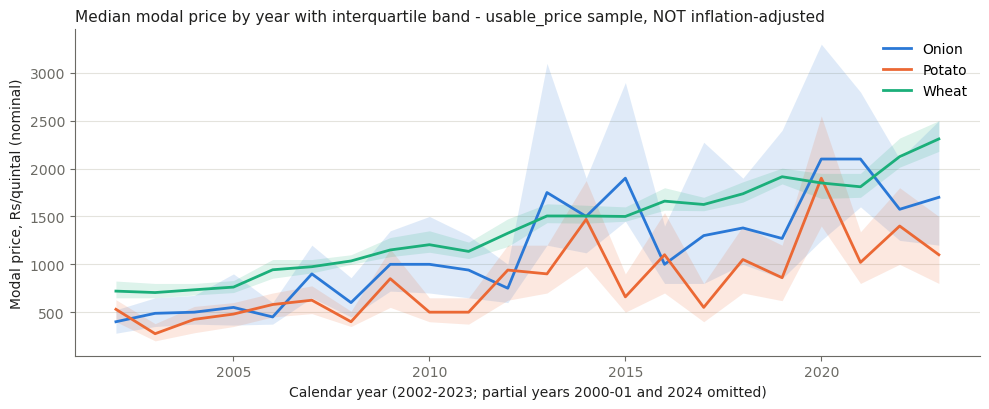

crop,Onion,Potato,Wheat
year,,,
2001,425.0,600.0,785.0
2002,400.0,530.0,720.0
2003,488.0,275.0,705.0
2004,500.0,425.0,734.0
2005,550.0,480.0,762.0
2006,450.0,580.0,943.0
2007,900.0,625.0,975.0
2008,600.0,400.0,1035.0
2009,1000.0,850.0,1150.0


In [5]:
y = R["yearly_profile"].query("variable == @f6.MODAL")
fig, ax = plt.subplots(figsize=(10, 4.2))
for crop in CROPS:
    d = y[(y["crop"] == crop) & y["year"].between(2002, 2023)]
    ax.plot(d["year"], d["median"], color=COLOR[crop], linewidth=2, label=crop)
    ax.fill_between(d["year"], d["p25"], d["p75"], color=COLOR[crop], alpha=0.15, linewidth=0)
ax.set_xlabel("Calendar year (2002-2023; partial years 2000-01 and 2024 omitted)")
ax.set_ylabel("Modal price, Rs/quintal (nominal)")
ax.set_title("Median modal price by year with interquartile band - usable_price sample, NOT inflation-adjusted",
             loc="left", color=INK, fontsize=11)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "phase07_nominal_price_trend.png", dpi=150); plt.show()
y.pivot(index="year", columns="crop", values="median")

Nominal median prices roughly tripled from the early 2000s to 2022–23 for Wheat (≈Rs 720 → 2,310) in a smooth, policy-like path, while Onion and Potato move in large irregular swings (e.g. Onion 2013, 2015, 2020–21; Potato 2014, 2020) on top of the upward drift. Because these are nominal rupees, part of the upward drift is general inflation; the figure should not be read as a real price increase. The composition of reporting markets also changes over time (Section 9), so yearly medians mix price change with coverage change.

### 4c. Seasonality (relative to each series' own year)

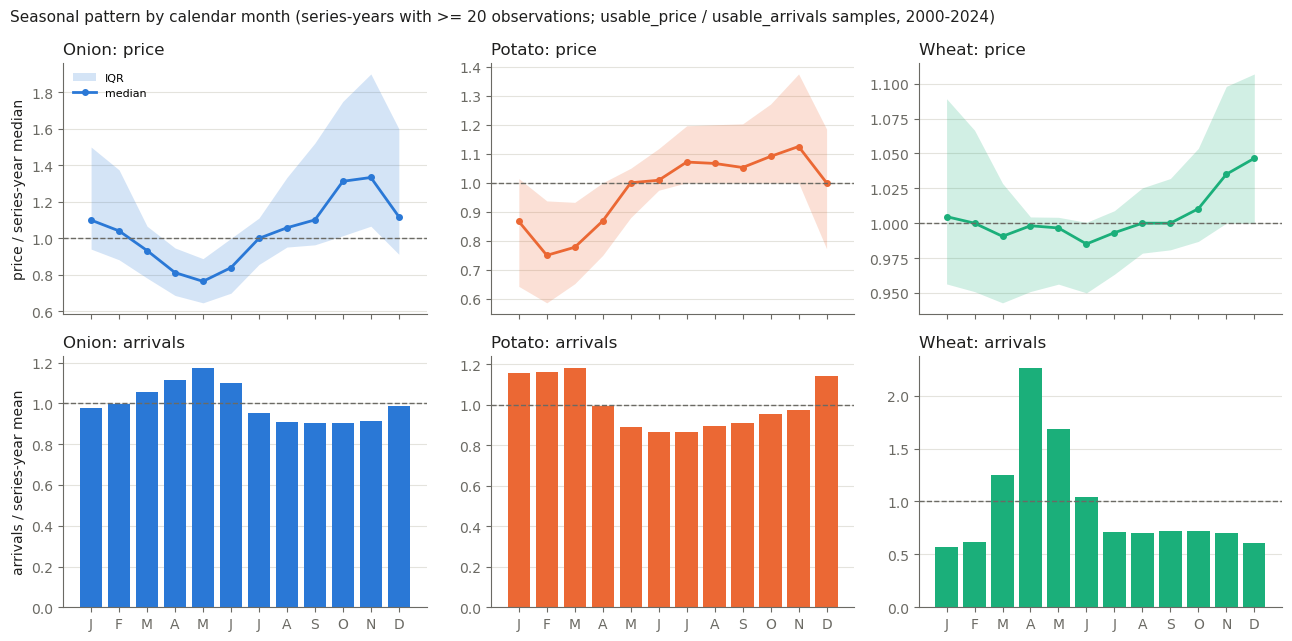

crop               Onion                                                              Potato                                                               Wheat                             \
variable arrivals_tonnes modal_price_rs_per_quintal                          arrivals_tonnes modal_price_rs_per_quintal                          arrivals_tonnes modal_price_rs_per_quintal   
sample   usable_arrivals               usable_price usable_price_excl_review usable_arrivals               usable_price usable_price_excl_review usable_arrivals               usable_price   
month                                                                                                                                                                                         
1                  1.000                      1.100                    1.099           1.045                      0.867                    0.867           0.708                      1.005   
2                  1.000                      1.041                    1.040           1.076                      0.750                    0.750           0.741                      1.000   
3                  1.000                      0.933                    0.933           1.063                      0.778                    0.778           1.040                      0.991   
4                  1.031                      0.812                    0.813           1.000                      0.868                    0.868           2.449                      0.998   
5                  1.083                      0.765                    0.765           1.000                      1.000                    1.000           1.970                      0.997   
6                  1.000                      0.840                    0.838           0.967                      1.009                    1.009           1.284                      0.985   
7                  1.000                      1.000                    1.000           0.965                      1.071                    1.071           1.000                      0.993   
8                  1.000                      1.058                    1.058           1.000                      1.067                    1.067           0.958                      1.000   
9                  1.000                      1.101                    1.102           1.000                      1.053                    1.053           0.980                      1.000   
10                 1.000                      1.312                    1.311           1.000                      1.091                    1.091           0.939                      1.010   
11                 1.000                      1.333                    1.333           1.000                      1.125                    1.125           0.929                      1.035   
12                 1.000                      1.119                    1.120           1.055                      1.000                    1.000           0.785                      1.047   

crop                               
variable                           
sample   usable_price_excl_review  
month                              
1                           1.005  
2                           1.000  
3                           0.991  
4                           0.998  
5                           0.997  
6                           0.985  
7                           0.993  
8                           1.000  
9                           1.000  
10                          1.010  
11                          1.035  
12                          1.047

In [6]:
s = R["seasonal_index"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
months = np.arange(1, 13)
for j, crop in enumerate(CROPS):
    p = s[(s["crop"] == crop) & (s["variable"] == f6.MODAL) & (s["sample"] == "usable_price")]
    ax = axes[0, j]
    ax.fill_between(months, p["p25_rel"], p["p75_rel"], color=COLOR[crop], alpha=0.2, linewidth=0, label="IQR")
    ax.plot(months, p["median_rel"], color=COLOR[crop], linewidth=2, marker="o", markersize=4, label="median")
    ax.axhline(1, color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(f"{crop}: price", loc="left", color=INK)
    a = s[(s["crop"] == crop) & (s["variable"] == f6.ARR)]
    ax2 = axes[1, j]
    ax2.bar(months, a["mean_rel_to_series_year_mean"], color=COLOR[crop])
    ax2.axhline(1, color=MUTED, linewidth=1, linestyle="--")
    ax2.set_title(f"{crop}: arrivals", loc="left", color=INK)
    ax2.set_xticks(months, [m[0] for m in e.MONTHS])
    for a_ in (ax, ax2):
        a_.yaxis.grid(True, color=GRID); a_.set_axisbelow(True)
axes[0, 0].set_ylabel("price / series-year median")
axes[1, 0].set_ylabel("arrivals / series-year mean")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Seasonal pattern by calendar month (series-years with >= 20 observations; usable_price / usable_arrivals samples, 2000-2024)",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "phase07_seasonal_index_price_arrivals.png", dpi=150); plt.show()
s.pivot_table(index="month", columns=["crop", "variable", "sample"], values="median_rel").round(3)

- **Onion**: prices are lowest in Apr–Jun (≈0.77–0.84 of the series-year median) and highest in Oct–Nov (≈1.31–1.33); arrivals are highest Mar–Jun (≈1.06–1.18 of the series-year mean). This is consistent with the large rabi-onion harvest reaching markets in spring, followed by depletion of stored stock before the kharif crop — but the data show co-movement only.
- **Potato**: prices lowest in Feb–Mar (≈0.75–0.78), highest Oct–Nov (≈1.09–1.13); arrivals highest Dec–Mar (≈1.14–1.18).
- **Wheat**: prices are almost flat across months (0.985–1.047), while arrivals spike in April (≈2.3× the series-year mean) and May (≈1.7×) — the procurement peak; this supports Phase 5's decision not to treat April arrival peaks as errors.
- Excluding `review` rows changes no monthly median by more than 0.002 (table above).

### 4d. Markets, varieties and volatility

In [7]:
v = R["variety_summary"]
display(v.groupby("crop").head(5)[["crop", "variety", "usable_price_rows", "share_of_usable_rows", "series",
                                    "median_modal", "p25_modal", "p75_modal"]].round(3))
se = R["series_summary"]
se[se["usable_price_rows"] >= 30].groupby("crop")[["cv_modal", "median_abs_pct_change", "reporting_density"]].describe(
    percentiles=[0.25, 0.5, 0.75]).round(3).T

,crop,variety,usable_price_rows,share_of_usable_rows,series,median_modal,p25_modal,p75_modal
0,Onion,Other,1349865,0.520,1320,1200.0,750.0,1850.0
1,Onion,Red,518694,0.200,477,1300.0,900.0,1900.0
2,Onion,Onion,289141,0.111,608,1400.0,850.0,2200.0
3,Onion,Nasik,92279,0.036,239,1460.0,950.0,2200.0
4,Onion,Local,86497,0.033,309,1000.0,650.0,1600.0
25,Potato,Other,1412146,0.517,1304,800.0,500.0,1250.0
26,Potato,Potato,414110,0.152,694,985.0,620.0,1500.0
27,Potato,Desi,342112,0.125,443,850.0,575.0,1180.0
28,Potato,Jyoti,205726,0.075,169,1000.0,620.0,1425.0
29,Potato,Local,139958,0.051,395,950.0,600.0,1450.0


crop                            Onion    Potato     Wheat
cv_modal              count  2629.000  2788.000  3160.000
                      mean      0.503     0.392     0.174
                      std       0.187     0.165     0.100
                      min       0.000     0.000     0.000
                      25%       0.384     0.274     0.101
                      50%       0.512     0.398     0.163
                      75%       0.618     0.497     0.234
                      max       2.006     2.564     1.161
median_abs_pct_change count  2629.000  2788.000  3160.000
                      mean      0.043     0.030     0.014
                      std       0.049     0.040     0.019
                      min       0.000     0.000     0.000
                      25%       0.000     0.000     0.000
                      50%       0.032     0.014     0.008
                      75%       0.065     0.048     0.020
                      max       0.513     0.375     0.167
reporting_density     count  2629.000  2788.000  3160.000
                      mean      0.339     0.368     0.256
                      std       0.246     0.256     0.222
                      min       0.005     0.006     0.005
                      25%       0.122     0.134     0.059
                      50%       0.298     0.330     0.191
                      75%       0.524     0.576     0.420
                      max       0.994     1.000     0.981

- "Other" is the largest variety label for every crop (≈49–52% of usable rows) — a generic source category, so variety is only partly informative; named varieties differ in median price (e.g. Wheat Dara Rs 1,730 vs Other Rs 1,515).
- Among series with ≥ 30 usable observations, the median within-series coefficient of variation is ≈0.51 (Onion), ≈0.40 (Potato), ≈0.16 (Wheat), and the median absolute change between consecutive observations is ≈3.2%, ≈1.4% and ≈0.8% — the same ordering as the pooled volatility.
- Reporting density (distinct reported days ÷ days between first and last report) has a median of only ≈0.30 / 0.33 / 0.19 for these series: most series report on a minority of calendar days.

<a id="5"></a>
## 5. Market-Arrivals EDA

In [8]:
display(dist[dist["variable"] == f6.ARR].drop(columns="variable").round(2))
ya = R["yearly_profile"].query("variable == @f6.ARR")
ya.pivot(index="year", columns="crop", values=["markets_active", "median"])

,crop,sample,rows_in_sample,non_missing,min,mean,std,p01,p05,p25,p50,p75,p95,p99,max,cv
3,Onion,all_rows,2623671,2623671,0.0,92.11,476.87,0.10,0.3,1.5,5.90,27.4,395.0,1753.73,244420.0,5.18
4,Onion,usable_arrivals,2623528,2623528,0.0,91.76,432.86,0.10,0.3,1.5,5.88,27.3,395.0,1752.00,61959.0,4.72
5,Onion,usable_arrivals_excl_review,2623129,2623129,0.0,91.67,432.04,0.10,0.3,1.5,5.83,27.3,394.7,1751.00,61959.0,4.71
9,Potato,all_rows,2764417,2764417,0.0,76.64,456.20,0.10,0.4,2.4,10.00,43.0,300.0,1156.40,212350.0,5.95
10,Potato,usable_arrivals,2764191,2764191,0.0,76.46,449.80,0.10,0.4,2.4,10.00,43.0,300.0,1154.00,212350.0,5.88
11,Potato,usable_arrivals_excl_review,2763792,2763792,0.0,76.23,442.92,0.10,0.4,2.4,10.00,43.0,300.0,1150.00,212350.0,5.81
15,Wheat,all_rows,2593279,2593279,0.0,227.36,5842.51,0.19,1.0,5.9,23.20,86.3,681.6,3318.00,8389090.0,25.70
16,Wheat,usable_arrivals,2593120,2593120,0.0,226.24,5719.51,0.19,1.0,5.9,23.20,86.3,681.1,3316.00,8389090.0,25.28
17,Wheat,usable_arrivals_excl_review,2592636,2592636,0.0,223.02,5643.01,0.19,1.0,5.9,23.13,86.2,680.0,3300.00,8389090.0,25.30


markets_active                 median               
crop          Onion  Potato   Wheat  Onion Potato   Wheat
year                                                     
2000            1.0     1.0     NaN    9.3  16.00     NaN
2001           20.0    21.0    14.0   93.0  79.00  70.000
2002          175.0   153.0   201.0   35.0  30.00  37.500
2003          329.0   314.0   409.0   15.0  23.00  31.000
2004          349.0   319.0   468.0   15.0  20.00  28.300
2005          517.0   487.0   700.0   11.6  20.00  17.500
2006          612.0   589.0   933.0    7.0  14.00  20.700
2007          657.0   646.0   998.0    6.0  11.50  25.300
2008          679.0   669.0  1023.0    5.0  10.40  30.000
2009          750.0   737.0  1122.0    6.0  10.10  20.000
2010          859.0   835.0  1180.0    5.0  11.00  18.065
2011          836.0   830.0  1108.0    5.0  11.20  26.000
2012          856.0   848.0  1141.0    6.4  11.00  26.000
2013          867.0   858.0  1157.0    5.0  11.00  25.000
2014          949.0   959.0  1254.0    6.0  10.00  26.000
2015          955.0   972.0  1300.0    6.0  10.78  24.300
2016          939.0   926.0  1281.0    7.3  10.00  19.400
2017          940.0   945.0  1306.0    6.0  11.30  21.000
2018          947.0   962.0  1332.0    5.1  10.00  20.000
2019          951.0   945.0  1274.0    5.0  10.00  22.000
2020          924.0   922.0  1112.0    4.5   8.00  20.000
2021          907.0   906.0  1124.0    4.4   8.00  22.000
2022         1031.0  1007.0  1135.0    5.1   8.50  27.500
2023         1065.0  1029.0  1158.0    5.5   8.40  30.000
2024          788.0   778.0   660.0    5.4  10.00  19.600

- Arrivals are extremely skewed (pooled CV 4.7–25): the median market-day handles ≈6 t (Onion), 10 t (Potato) and 23 t (Wheat), while the top 1% exceed ≈1,150–3,300 t. Large values are concentrated in big terminal and procurement markets; Phase 5 left them in place unless they exceeded 100× the market's own past peak.
- Wheat's maximum (8.39 Mt in one market-day) is retained in the `usable_arrivals` sample because its market had insufficient prior history for the Phase 5 rule to judge it; it dominates Wheat's arrivals mean and standard deviation. **Arrivals analyses should use medians, logs or per-market scaling.**
- The number of reporting markets grows strongly until ≈2014 and dips in 2020–2021; yearly arrival *totals* therefore mostly track reporting coverage and are not a production trend.

<a id="6"></a>
## 6. Price–Arrivals Association

In [9]:
R["relationship_summary"].round(3)

,crop,relationship,sample,series,median_spearman,p25,p75,share_negative
0,Onion,same-day modal price vs arrivals (within series),usable_price & usable_arrivals,2345,-0.150,-0.328,0.038,0.707
1,Onion,modal price vs previous observation (within series),usable_price,2342,0.951,0.899,0.975,0.000
2,Onion,price / trailing-90d mean vs wx_rain_sum_30d (within series),usable_price with weather features,549,0.349,0.248,0.461,0.062
3,Onion,price / trailing-90d mean vs wx_temp_mean_mean_30d (within series),usable_price with weather features,549,0.073,-0.160,0.239,0.399
4,Potato,same-day modal price vs arrivals (within series),usable_price & usable_arrivals,2487,-0.144,-0.348,0.044,0.696
5,Potato,modal price vs previous observation (within series),usable_price,2482,0.949,0.884,0.976,0.000
6,Potato,price / trailing-90d mean vs wx_rain_sum_30d (within series),usable_price with weather features,485,0.169,0.073,0.295,0.136
7,Potato,price / trailing-90d mean vs wx_temp_mean_mean_30d (within series),usable_price with weather features,485,0.405,0.181,0.500,0.169
8,Wheat,same-day modal price vs arrivals (within series),usable_price & usable_arrivals,2732,-0.038,-0.240,0.169,0.553
9,Wheat,modal price vs previous observation (within series),usable_price,2724,0.956,0.879,0.984,0.000


Within a series, same-day price and arrivals are **weakly negatively** associated for Onion and Potato (median Spearman ≈ −0.15 and −0.14; negative in ≈70% of series) and essentially unrelated for Wheat (−0.04). The association is modest and partly seasonal (both move with the harvest calendar), so it is not evidence of a demand curve or of arrivals causing prices. Price persistence is very strong: the within-series rank correlation between a price and the series' previous observation has a median of ≈0.95 for all crops.

<a id="7"></a>
## 7. Weather Association (covered subset only)

In [10]:
sp = R["split_evidence"]
print("Share of usable price rows with trailing weather features, by year:")
display(sp.pivot(index="year", columns="crop", values="share_rows_with_weather_features").round(3).T)
R["relationship_summary"][R["relationship_summary"]["relationship"].str.contains("wx_")].round(3)

Share of usable price rows with trailing weather features, by year:


year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
crop,,,,,,,,,,,,,,,,,,,,,,,,
Onion,0.244,0.204,0.206,0.207,0.199,0.232,0.258,0.239,0.253,0.268,0.260,0.276,0.282,0.286,0.283,0.298,0.300,0.297,0.294,0.275,0.305,0.282,0.0,0.0
Potato,0.219,0.256,0.225,0.228,0.210,0.248,0.255,0.251,0.246,0.258,0.260,0.271,0.272,0.273,0.256,0.274,0.269,0.264,0.259,0.242,0.267,0.239,0.0,0.0
Wheat,0.377,0.285,0.254,0.276,0.293,0.272,0.274,0.257,0.279,0.289,0.268,0.274,0.271,0.269,0.271,0.281,0.263,0.255,0.258,0.264,0.262,0.281,0.0,0.0


,crop,relationship,sample,series,median_spearman,p25,p75,share_negative
2,Onion,price / trailing-90d mean vs wx_rain_sum_30d (within series),usable_price with weather features,549,0.349,0.248,0.461,0.062
3,Onion,price / trailing-90d mean vs wx_temp_mean_mean_30d (within series),usable_price with weather features,549,0.073,-0.160,0.239,0.399
6,Potato,price / trailing-90d mean vs wx_rain_sum_30d (within series),usable_price with weather features,485,0.169,0.073,0.295,0.136
7,Potato,price / trailing-90d mean vs wx_temp_mean_mean_30d (within series),usable_price with weather features,485,0.405,0.181,0.500,0.169
10,Wheat,price / trailing-90d mean vs wx_rain_sum_30d (within series),usable_price with weather features,666,0.020,-0.104,0.134,0.441
11,Wheat,price / trailing-90d mean vs wx_temp_mean_mean_30d (within series),usable_price with weather features,666,-0.099,-0.194,-0.002,0.751


- Weather features exist for ≈20–30% of usable price rows in most years (up to 38% in the partial year 2001) and for **none after 2022-12-31** (Phase 3/4 collection window); they come from 46 high-volume districts only, so the covered subset is not a random sample of markets.
- On that subset, price relative to its trailing 90-day mean is positively associated with 30-day rainfall for Onion (median Spearman 0.35) and with 30-day temperature for Potato (0.41); Wheat shows essentially no association. **These coincide with the seasonal calendar** (monsoon months are also Onion's rising-price months), so they are likely seasonal confounding, not weather effects. Any weather-feature benefit must be judged against a calendar-only baseline in Phase 8.

<a id="8"></a>
## 8. APY Association (district-year grain)

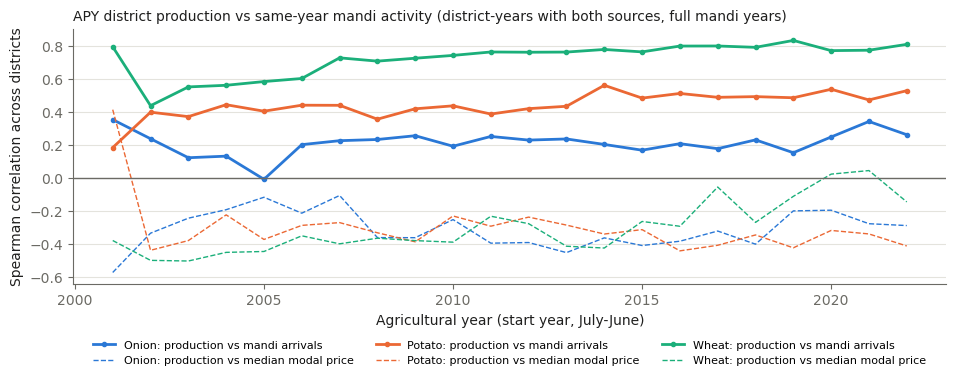

,districts,spearman_production_vs_mandi_arrivals,spearman_production_vs_median_modal
crop,,,
Onion,192.5,0.228,-0.328
Potato,226.5,0.441,-0.335
Wheat,296.5,0.764,-0.357


In [11]:
ap = R["apy_district_year_association"]
fig, ax = plt.subplots(figsize=(10, 4))
for crop in CROPS:
    d = ap[ap["crop"] == crop]
    yrs = d["apy_year"].str[:4].astype(int)
    ax.plot(yrs, d["spearman_production_vs_mandi_arrivals"], color=COLOR[crop], linewidth=2, marker="o", markersize=3,
            label=f"{crop}: production vs mandi arrivals")
    ax.plot(yrs, d["spearman_production_vs_median_modal"], color=COLOR[crop], linewidth=1, linestyle="--",
            label=f"{crop}: production vs median modal price")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Agricultural year (start year, July-June)")
ax.set_ylabel("Spearman correlation across districts")
ax.set_title("APY district production vs same-year mandi activity (district-years with both sources, full mandi years)",
             loc="left", color=INK, fontsize=10)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout(); fig.savefig(FIG / "phase07_apy_district_association.png", dpi=150, bbox_inches="tight"); plt.show()
ap.groupby("crop")[["districts", "spearman_production_vs_mandi_arrivals", "spearman_production_vs_median_modal"]].median().round(3)

- Across districts, higher APY production goes with higher mandi arrivals in the same agricultural year — strongly for Wheat (median Spearman ≈0.76), moderately for Potato (≈0.44) and weakly for Onion (≈0.23) — and with somewhat lower median prices (≈−0.33 to −0.36). These are cross-sectional associations: big producing districts host big markets and often lower farm-gate prices; they do not show that production changes prices over time.
- APY lag-2 features are missing for 51% (Onion), 34% (Potato) and 4% (Wheat) of rows (Phase 6), so APY-based features are realistic mainly for Wheat.

<a id="9"></a>
## 9. Data Quality and Modelling Readiness

In [12]:
q = R["quality_readiness"]
display(q[~q["metric"].str.startswith("missing %")].pivot(index="metric", columns="crop", values="value"))
c = R["conflict_distribution"]
print("Unresolved conflicts (Phase 5) by state (top) and year - kept visible, excluded from usable views:")
display(c.groupby(["crop", "state"])["conflict_rows"].sum().unstack(0).fillna(0).astype(int).sort_values("Potato", ascending=False).head(8))
c.groupby(["crop", "year"])["conflict_rows"].sum().unstack(0).fillna(0).astype(int).T

crop,Onion,Potato,Wheat
metric,,,
arrivals entry_error_suspected rows,75,62,53
arrivals review rows,399,399,484
conflict_unresolved rows,68,164,106
first_date,2000-10-19,2000-10-19,2001-03-16
last_date,2024-02-02,2024-02-02,2024-02-01
markets,1732,1624,1988
modal target missing (of all rows),27474,32511,13331
price review rows,22330,2339,471
price scale_error_suspected rows,422,415,148


Unresolved conflicts (Phase 5) by state (top) and year - kept visible, excluded from usable views:


crop,Onion,Potato,Wheat
state,,,
Telangana,12,116,0
Punjab,22,22,8
Odisha,6,14,0
West Bengal,0,8,16
Karnataka,8,2,6
Uttar Pradesh,6,2,4
Haryana,10,0,0
Madhya Pradesh,0,0,68


year,2002,2003,2004,2005,2006,2007,2008,2010,2011,2013,2014,2015,2016,2017,2018
crop,,,,,,,,,,,,,,,
Onion,2,4,8,10,18,0,4,0,2,4,2,8,2,2,2
Potato,0,6,10,4,10,2,0,72,52,6,0,2,0,0,0
Wheat,4,4,6,0,66,0,0,14,0,4,4,4,0,0,0


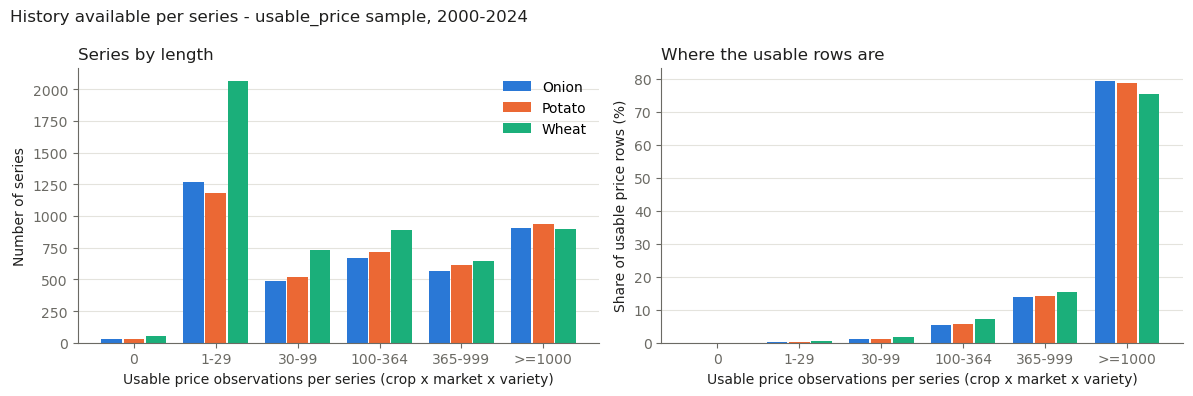

Onion             Potato              Wheat            
                  series usable rows series usable rows series usable rows
usable_price_rows                                                         
0                     27           0     32           0     52           0
1-29                1268        9358   1183        8936   2067       15677
30-99                488       27995    519       29990    734       42204
100-364              668      137338    718      152397    886      185872
365-999              566      360114    611      390327    646      394991
>=1000               907     2060806    940     2149621    894     1940271

In [13]:
se = R["series_summary"]
bins = [0, 1, 30, 100, 365, 1000, 10**7]
labels = ["0", "1-29", "30-99", "100-364", "365-999", ">=1000"]
tab = {}
for crop in CROPS:
    g = se[se["crop"] == crop]
    cat = pd.cut(g["usable_price_rows"], bins, right=False, labels=labels)
    tab[(crop, "series")] = cat.value_counts().reindex(labels)
    tab[(crop, "usable rows")] = g.groupby(cat, observed=False)["usable_price_rows"].sum().reindex(labels)
tab = pd.DataFrame(tab)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.arange(len(labels))
for i, crop in enumerate(CROPS):
    axes[0].bar(xx + (i - 1) * 0.27, tab[(crop, "series")], 0.25, color=COLOR[crop], label=crop)
    share = tab[(crop, "usable rows")] / tab[(crop, "usable rows")].sum() * 100
    axes[1].bar(xx + (i - 1) * 0.27, share, 0.25, color=COLOR[crop], label=crop)
for ax, yl, t in [(axes[0], "Number of series", "Series by length"),
                  (axes[1], "Share of usable price rows (%)", "Where the usable rows are")]:
    ax.set_xticks(xx, labels); ax.set_xlabel("Usable price observations per series (crop x market x variety)")
    ax.set_ylabel(yl); ax.set_title(t, loc="left", color=INK)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend(frameon=False)
fig.suptitle("History available per series - usable_price sample, 2000-2024", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG / "phase07_series_history_coverage.png", dpi=150); plt.show()
tab

In [14]:
pm = q[q["metric"].str.startswith("missing % (predictor)")].copy()
pm["feature"] = pm["metric"].str.replace("missing % (predictor) ", "", regex=False)
key = ["modal_prev_obs", "modal_lag_1d", "modal_lag_7d", "modal_roll7d_mean", "modal_roll30d_mean", "modal_roll90d_mean",
       "modal_roll30d_std", "arrivals_prev_obs", "arrivals_roll30d_mean", "wx_rain_sum_30d", "wx_temp_mean_mean_30d",
       "apy_production_tonnes_lag2"]
pm[pm["feature"].isin(key)].pivot(index="feature", columns="crop", values="value").loc[key]

crop,Onion,Potato,Wheat
feature,,,
modal_prev_obs,0.433,0.454,0.319
modal_lag_1d,28.828,25.336,34.294
modal_lag_7d,24.337,22.417,28.839
modal_roll7d_mean,3.695,3.384,4.549
modal_roll30d_mean,1.733,1.745,1.724
modal_roll90d_mean,1.233,1.29,1.065
modal_roll30d_std,2.655,2.553,3.099
arrivals_prev_obs,0.15,0.145,0.204
arrivals_roll30d_mean,0.89,0.79,1.398


**Readiness findings** (denominator: all Phase 6 rows of the crop):
- 3,924 / 4,003 / 5,279 series; 30–40% have < 30 usable observations, but series with ≥ 365 usable observations (1,473 / 1,551 / 1,540) hold ≈90–93% of all usable price rows. Short series are numerous but carry little data.
- Targets: 1.1% / 1.2% / 0.6% of rows are not in `usable_modal_price`; < 0.01% are not in `usable_arrivals`.
- Unresolved conflicts: 68 / 164 / 106 rows, concentrated in Telangana, Madhya Pradesh and Punjab and in 2006 and 2010–2011; none after 2018.
- History features: previous-observation lags are almost always present (≈0.3–0.5% missing); exact calendar lags are missing 22–34%; weather 75–76%; APY lag-2 51% / 34% / 4%.

**Candidate modelling scope (evidence, not a final rule)**: series with ≥ 365 usable observations and active in the evaluation period cover most of the data; whether to also require regular reporting (e.g. a span of ≥ 2 years and density ≥ 0.5, which keeps only 491 / 592 / 335 series and 45% / 51% / 32% of usable rows) is a trade-off between regularity and coverage that Phase 8 must choose explicitly (see `Modelling_Readiness_Report.md`).

<a id="10"></a>
## 10. Decision A — Forecast Horizon and Information Cutoff

Three different tasks:
1. **Next reported observation** — predict the series' next usable price, whenever it occurs. Phase 6 features (data strictly before the row's date) are valid as-is; the horizon is irregular (median gap 1 day, p90 3–4 days).
2. **Specific future calendar day** — predict the price on day o+h. The target exists only if the series reports exactly that day.
3. **Several days/weeks ahead** — predict the level over a future period from an origin o, using only information ≤ o.

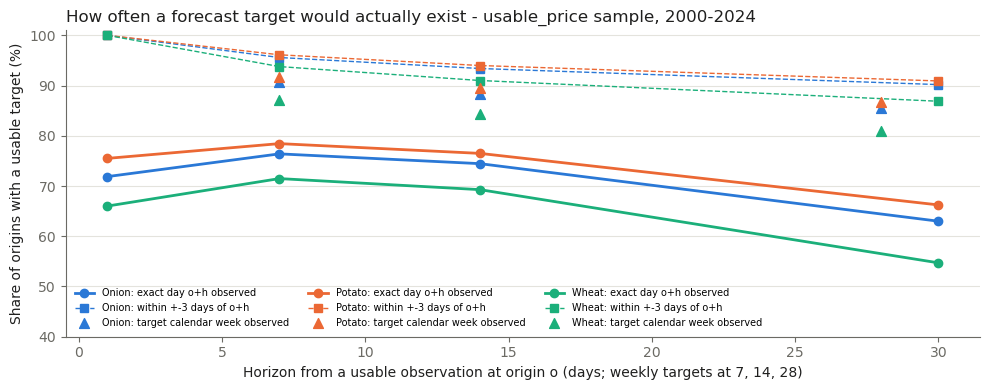

,crop,horizon_days,origins,share_exact_day_observed,share_observed_within_pm3d,next_obs_gap_median_days,next_obs_gap_p90_days
0,Onion,1,2595611,0.719,1.000,1.0,3.0
1,Onion,7,2595611,0.764,0.956,1.0,3.0
2,Onion,14,2595611,0.745,0.934,1.0,3.0
3,Onion,30,2595611,0.630,0.902,1.0,3.0
4,Potato,1,2731271,0.755,1.000,1.0,3.0
5,Potato,7,2731271,0.784,0.961,1.0,3.0
6,Potato,14,2731271,0.765,0.940,1.0,3.0
7,Potato,30,2731271,0.662,0.909,1.0,3.0
8,Wheat,1,2579015,0.660,1.000,1.0,4.0
9,Wheat,7,2579015,0.715,0.938,1.0,4.0


,crop,horizon_weeks,origin_series_weeks,share_target_week_observed
0,Onion,1,611072,0.907
1,Onion,2,611072,0.884
2,Onion,4,611072,0.856
3,Potato,1,603287,0.917
4,Potato,2,603287,0.894
5,Potato,4,603287,0.868
6,Wheat,1,662171,0.871
7,Wheat,2,662171,0.843
8,Wheat,4,662171,0.810


In [15]:
h = R["horizon_feasibility"]
w = R["weekly_horizon_feasibility"]
fig, ax = plt.subplots(figsize=(10, 4))
for crop in CROPS:
    d = h[h["crop"] == crop]
    ax.plot(d["horizon_days"], d["share_exact_day_observed"] * 100, color=COLOR[crop], marker="o", linewidth=2,
            label=f"{crop}: exact day o+h observed")
    ax.plot(d["horizon_days"], d["share_observed_within_pm3d"] * 100, color=COLOR[crop], marker="s", linewidth=1,
            linestyle="--", label=f"{crop}: within +-3 days of o+h")
    ww = w[w["crop"] == crop]
    ax.scatter(ww["horizon_weeks"] * 7, ww["share_target_week_observed"] * 100, color=COLOR[crop], marker="^", s=50,
               label=f"{crop}: target calendar week observed", zorder=3)
ax.set_xlabel("Horizon from a usable observation at origin o (days; weekly targets at 7, 14, 28)")
ax.set_ylabel("Share of origins with a usable target (%)")
ax.set_ylim(40, 101)
ax.set_title("How often a forecast target would actually exist - usable_price sample, 2000-2024", loc="left", color=INK)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=7, ncol=3)
fig.tight_layout(); fig.savefig(FIG / "phase07_horizon_feasibility.png", dpi=150); plt.show()
display(h.round(3)); w.round(3)

**Evidence**: an exact target day o+h is observed only 55–78% of the time (30 days: 55% Wheat, 63% Onion, 66% Potato), whereas the target **calendar week** h weeks ahead holds at least one usable price 81–92% of the time. Exact-day targets would silently select easier, more regularly reported periods and markets.

**Proposed decision (D-38, for review)**: Phase 8's primary task = forecast the **weekly median usable modal price of a series for weeks h = 1, 2, 4 ahead** (≈7–28 days), from a forecast origin at the end of week W, using only information dated ≤ the origin date (Phase 6 features of the origin row or its week; any recomputation must keep the ≤-origin cutoff). Report "next reported observation" as a secondary, short-horizon baseline task. Do not use exact calendar-day targets. Phase 6 feature calculations stay unchanged.

<a id="11"></a>
## 11. Decision B — Flagged Observations

In [16]:
R["review_flag_effect"].round(3)

,crop,variable,rows_with,rows_without,review_rows,review_share,median_with,median_without,mean_with,mean_without,std_with,std_without,p99_with,p99_without
0,Onion,modal_price_rs_per_quintal,2595611,2573328,22283,0.009,1300.00,1300.00,1605.571,1602.498,1265.390,1182.708,5850.0,5800.0
1,Onion,arrivals_tonnes,2623528,2623129,399,0.000,5.88,5.83,91.762,91.673,432.856,432.044,1752.0,1751.0
2,Potato,modal_price_rs_per_quintal,2731271,2728946,2325,0.001,850.00,850.00,1039.740,1034.999,784.976,696.371,3500.0,3500.0
3,Potato,arrivals_tonnes,2764191,2763792,399,0.000,10.00,10.00,76.458,76.226,449.804,442.920,1154.0,1150.0
4,Wheat,modal_price_rs_per_quintal,2579015,2578561,454,0.000,1580.00,1580.00,1574.544,1574.540,494.189,491.126,2800.0,2800.0
5,Wheat,arrivals_tonnes,2593120,2592636,484,0.000,23.20,23.13,226.244,223.017,5719.509,5643.013,3316.0,3300.0


**Evidence**: `review` rows are 0.86% of Onion usable prices (22,283 rows; reflecting genuine onion price spikes), 0.09% Potato and 0.02% Wheat. Including them leaves medians and p99 essentially unchanged but raises standard deviations (Onion +7%, Potato +13%). Suspected scale/entry errors (422 / 415 / 148 price rows; 75 / 62 / 53 arrivals rows) and the 338 unresolved conflicts are already outside the usable views.

**Proposed decision (D-39, for review)**: (1) train and evaluate only on `usable_modal_price` / `usable_arrivals` rows — i.e. exclude suspected scale/entry errors and unresolved conflicts from targets *and* history (already the Phase 6 history rule); (2) **retain `review` rows** in the primary experiments, because they are plausible extreme market events and the forecasting system must handle them; (3) run a sensitivity analysis excluding `review` targets and report both, especially for Onion; (4) never delete flagged rows — all flags and `source_row` stay in the data.

<a id="12"></a>
## 12. Decision C — Evaluation Split

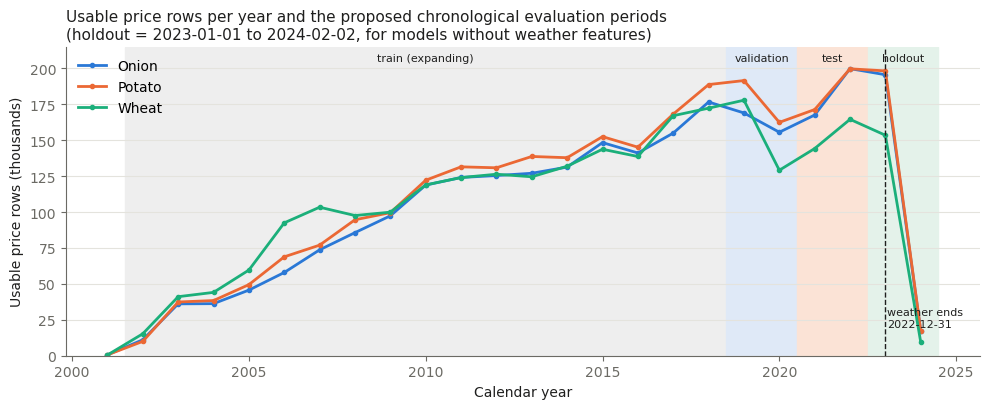

usable_price_rows                     series_active                 series_with_earlier_history                
crop             Onion    Potato     Wheat         Onion  Potato   Wheat                       Onion  Potato   Wheat
year                                                                                                                
2001             651.0     597.0     517.0          30.0    24.0    30.0                         0.0     0.0     0.0
2002           11101.0    9985.0   15289.0         243.0   208.0   358.0                        25.0    18.0    13.0
2003           36096.0   37379.0   41075.0         498.0   474.0   686.0                       182.0   161.0   257.0
2004           36226.0   38389.0   44076.0         470.0   441.0   693.0                       350.0   342.0   435.0
2005           45657.0   49465.0   59604.0         674.0   686.0  1005.0                       403.0   391.0   590.0
2006           57918.0   68811.0   92454.0         802.0   810.0  1444.0                       521.0   533.0   804.0
2007           73677.0   76946.0  103339.0         853.0   814.0  1452.0                       619.0   568.0  1038.0
2008           85640.0   94601.0   97547.0         852.0   830.0  1384.0                       678.0   651.0  1142.0
2009           97346.0   99547.0   99890.0         963.0   928.0  1589.0                       752.0   718.0  1209.0
2010          118720.0  122118.0  118856.0        1199.0  1125.0  1619.0                       849.0   795.0  1261.0
2011          124030.0  131429.0  123965.0        1099.0  1038.0  1486.0                       936.0   886.0  1287.0
2012          125365.0  130760.0  126287.0        1136.0  1102.0  1473.0                       941.0   905.0  1315.0
2013          126961.0  138646.0  124518.0        1190.0  1137.0  1506.0                      1018.0   976.0  1325.0
2014          131256.0  137776.0  131849.0        1382.0  1408.0  1743.0                      1144.0  1109.0  1462.0
2015          148295.0  152453.0  143668.0        1256.0  1203.0  1661.0                      1099.0  1060.0  1508.0
2016          141078.0  145102.0  138626.0        1199.0  1127.0  1609.0                      1104.0  1056.0  1527.0
2017          154916.0  168127.0  167014.0        1273.0  1252.0  1660.0                      1158.0  1112.0  1509.0
2018          176540.0  188671.0  172250.0        1231.0  1244.0  1697.0                      1141.0  1115.0  1566.0
2019          168923.0  191467.0  177792.0        1188.0  1197.0  1604.0                      1098.0  1098.0  1537.0
2020          155518.0  162380.0  129053.0        1119.0  1149.0  1340.0                      1064.0  1063.0  1307.0
2021          167485.0  171293.0  144170.0        1090.0  1093.0  1381.0                      1032.0  1036.0  1323.0
2022          199755.0  199638.0  164484.0        1236.0  1256.0  1411.0                      1100.0  1095.0  1370.0
2023          195507.0  198187.0  153407.0        1331.0  1302.0  1536.0                      1226.0  1208.0  1391.0
2024           16950.0   17504.0    9285.0         895.0   870.0   724.0                       872.0   851.0   688.0

In [17]:
sp = R["split_evidence"]
fig, ax = plt.subplots(figsize=(10, 4.2))
for crop in CROPS:
    d = sp[sp["crop"] == crop]
    ax.plot(d["year"], d["usable_price_rows"] / 1000, color=COLOR[crop], linewidth=2, marker="o", markersize=3, label=crop)
spans = [(2001.5, 2018.5, "train (expanding)", "#eeeeee"), (2018.5, 2020.5, "validation", "#dfe9f7"),
         (2020.5, 2022.5, "test", "#fbe3d6"), (2022.5, 2024.5, "no-weather holdout", "#e4f2ea")]
for a, b, lab, col in spans:
    ax.axvspan(a, b, color=col, zorder=0)
    ax.text((a + b) / 2, 205, lab.replace("no-weather holdout", "holdout"), ha="center", fontsize=8, color=INK)
ax.axvline(2022.99, color=INK, linestyle="--", linewidth=1)
ax.text(2023.05, 20, "weather ends\n2022-12-31", fontsize=8, color=INK)
ax.set_ylim(0, 215)
ax.set_xlabel("Calendar year"); ax.set_ylabel("Usable price rows (thousands)")
ax.set_title("Usable price rows per year and the proposed chronological evaluation periods\n"
             "(holdout = 2023-01-01 to 2024-02-02, for models without weather features)", loc="left", color=INK, fontsize=11)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "phase07_split_evidence.png", dpi=150); plt.show()
sp.pivot(index="year", columns="crop", values=["usable_price_rows", "series_active", "series_with_earlier_history"])

**Why not a random row split**: consecutive observations of a series are almost the same number (median within-series rank correlation with the previous observation ≈0.95). With a random split, a test row's neighbours — often the previous and next day of the same market — are in the training set, so a model can effectively interpolate and look far better than it would when forecasting the future. Rolling-window features would also straddle train and test.

**Evidence for a chronological design**: in 2021–2022, 87–97% of active series already had usable history in earlier years (`series_with_earlier_history`), so out-of-time testing does not mostly evaluate unseen series; weather features end on 2022-12-31; 2001 and 2024 are partial years; reporting dipped in 2020 (Wheat −27% rows).

**Proposed decision (D-40, for review)**: chronological, out-of-time evaluation with an expanding training window — train 2002–2018, validation 2019–2020 (for model/hyper-parameter choice), test 2021–2022 (weather and APY available; touched once), plus a 2023-01-01–2024-02-02 holdout for models that do not use weather features. Within that, use rolling forecast origins (e.g. monthly origins through the test period, each model trained only on data before the origin), leave a gap of at least the forecast horizon between the last training target and the first test origin, fit any scaler/encoder/imputer on training data only, and report metrics per crop, per horizon and for series with and without long history. Exact years must be confirmed in Phase 8 planning.

<a id="13"></a>
## 13. Validation

In [18]:
checks = {}
fp = R["input_fingerprints"]
checks["Phase 6 feature files unchanged during EDA (SHA-256)"] = bool(fp["unchanged"].all())
m6 = pd.read_csv(f6.AUDIT_DIR / "output_manifest.csv").set_index("file")
for crop in CROPS:
    df = pd.read_parquet(f6.FEATURE_DIR / f"features_{crop.lower()}.parquet")
    checks[f"{crop}: feature table content == Phase 6 manifest"] = (
        f6.frame_fingerprint(df) == m6.loc[f"features_{crop.lower()}.parquet", "content_sha256"])
    sd = R["sample_definitions"].query("crop == @crop").set_index("sample")["rows"]
    checks[f"{crop}: sample counts reproduce from the feature table"] = all(
        sd[k] == int(m.sum()) for k, m in e.masks(df).items())
    se_c = R["series_summary"].query("crop == @crop")
    checks[f"{crop}: series table covers every row once ({len(df):,})"] = int(se_c["rows"].sum()) == len(df)
    checks[f"{crop}: conflicts visible in EDA tables"] = (
        int(R["conflict_distribution"].query("crop == @crop")["conflict_rows"].sum())
        == int((df["dup_status"] == "conflict_unresolved").sum()))
    yr = R["yearly_profile"].query("crop == @crop and variable == @f6.MODAL")
    checks[f"{crop}: yearly usable rows sum to the usable sample"] = int(yr["rows"].sum()) == int(df["usable_modal_price"].sum())
    del df
s = R["seasonal_index"]
checks["Seasonal tables have exactly months 1-12 for every crop/variable/sample"] = bool(
    s.groupby(["crop", "variable", "sample"])["month"].apply(lambda m: sorted(m) == list(range(1, 13))).all())
for k, v in checks.items():
    print(("PASS" if v else "FAIL"), "-", k)
assert all(checks.values()), "Phase 7 validation failed"
print("\nAll Phase 7 notebook validation checks passed.")

PASS - Phase 6 feature files unchanged during EDA (SHA-256)
PASS - Onion: feature table content == Phase 6 manifest
PASS - Onion: sample counts reproduce from the feature table
PASS - Onion: series table covers every row once (2,623,671)
PASS - Onion: conflicts visible in EDA tables
PASS - Onion: yearly usable rows sum to the usable sample
PASS - Potato: feature table content == Phase 6 manifest
PASS - Potato: sample counts reproduce from the feature table
PASS - Potato: series table covers every row once (2,764,417)
PASS - Potato: conflicts visible in EDA tables
PASS - Potato: yearly usable rows sum to the usable sample
PASS - Wheat: feature table content == Phase 6 manifest
PASS - Wheat: sample counts reproduce from the feature table
PASS - Wheat: series table covers every row once (2,593,279)
PASS - Wheat: conflicts visible in EDA tables
PASS - Wheat: yearly usable rows sum to the usable sample
PASS - Seasonal tables have exactly months 1-12 for every crop/variable/sample

All Phase

In [19]:
tests = subprocess.run([sys.executable, "-m", "pytest", "Code/tests", "-q", "-p", "no:cacheprovider"],
                       capture_output=True, text=True)
print(tests.stdout[-3000:])
assert tests.returncode == 0, "Project test suite failed"
print("Full suite: Phases 4-7.")

.........................................................                [100%]
57 passed in 349.19s (0:05:49)

Full suite: Phases 4-7.


<a id="14"></a>
## 14. Findings, Limitations and Phase 8 Handoff

**Findings** are summarised in `Documentation/EDA_Findings.md`; data quality, candidate scope and the three proposed decisions in `Documentation/Modelling_Readiness_Report.md` and Decision Log D-38 – D-40.

**Limitations**: nominal prices only (no deflator in the project); reporting coverage changes over time, so pooled and yearly statistics mix price change with coverage change; weather associations are confounded with seasonality and cover a non-random 25% of rows ending in 2022; APY associations are cross-sectional; seasonal indices use calendar months for all regions; all results are associations, not causal effects.

**Phase 7 status: completed** (validation above). **Next**: Phase 8 planning — review and confirm D-38 – D-40 (target and horizon, flag policy, split years) before any model is trained.